(257673, 7)
(206138, 6) (51535, 6)
(206138, 6) (51535, 6)
{0: 9.623622782446311, 1: 11.06484165324745, 2: 1.5757376547928452, 3: 0.5787142055025267, 4: 1.0627313502087952, 5: 0.4376881754676519, 6: 0.2770672043010753, 7: 1.8423272857270534, 8: 17.050289495450787, 9: 148.30071942446042}
X_train_cnn: (206138, 6, 1)
X_test_cnn:  (51535, 6, 1)
num_classes: 10
n_features:  6
Model: "CNN_IDS_designed_16f"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 Input (InputLayer)          [(None, 6, 1)]               0         []                            
                                                                                                  
 B1_Conv3 (Conv1D)           (None, 6, 32)                128       ['Input[0][0]']               
                                                                                                  
 B1

/home/e-ackerson/anaconda3/envs/tf213_only/lib/python3.9/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


724/725 [============================>.] - ETA: 0s - loss: 1.4681 - accuracy: 0.5365
Epoch 2: val_accuracy did not improve from 0.59848
725/725 [==============================] - 10s 14ms/step - loss: 1.4679 - accuracy: 0.5366 - val_loss: 1.1132 - val_accuracy: 0.5429 - lr: 0.0010
Epoch 3/100
723/725 [============================>.] - ETA: 0s - loss: 1.4061 - accuracy: 0.5541
Epoch 3: val_accuracy did not improve from 0.59848
725/725 [==============================] - 10s 14ms/step - loss: 1.4059 - accuracy: 0.5540 - val_loss: 1.1127 - val_accuracy: 0.5825 - lr: 0.0010
Epoch 4/100
724/725 [============================>.] - ETA: 0s - loss: 1.3480 - accuracy: 0.5741
Epoch 4: val_accuracy did not improve from 0.59848
725/725 [==============================] - 10s 14ms/step - loss: 1.3477 - accuracy: 0.5741 - val_loss: 1.0884 - val_accuracy: 0.5644 - lr: 0.0010
Epoch 5/100
722/725 [============================>.] - ETA: 0s - loss: 1.3366 - accuracy: 0.5765
Epoch 5: val_accuracy improved fr

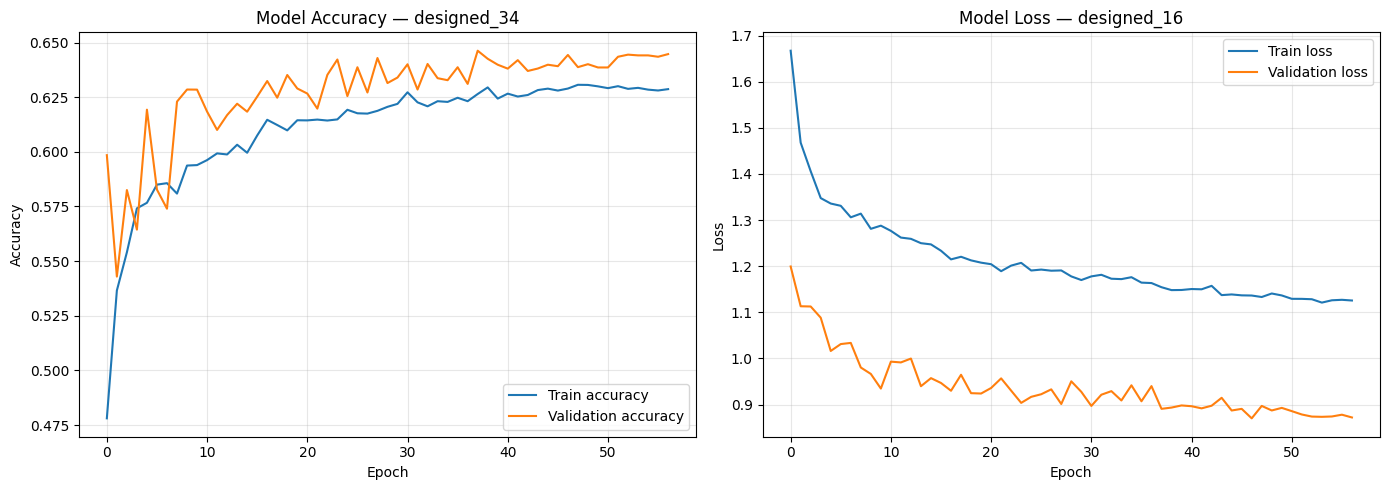

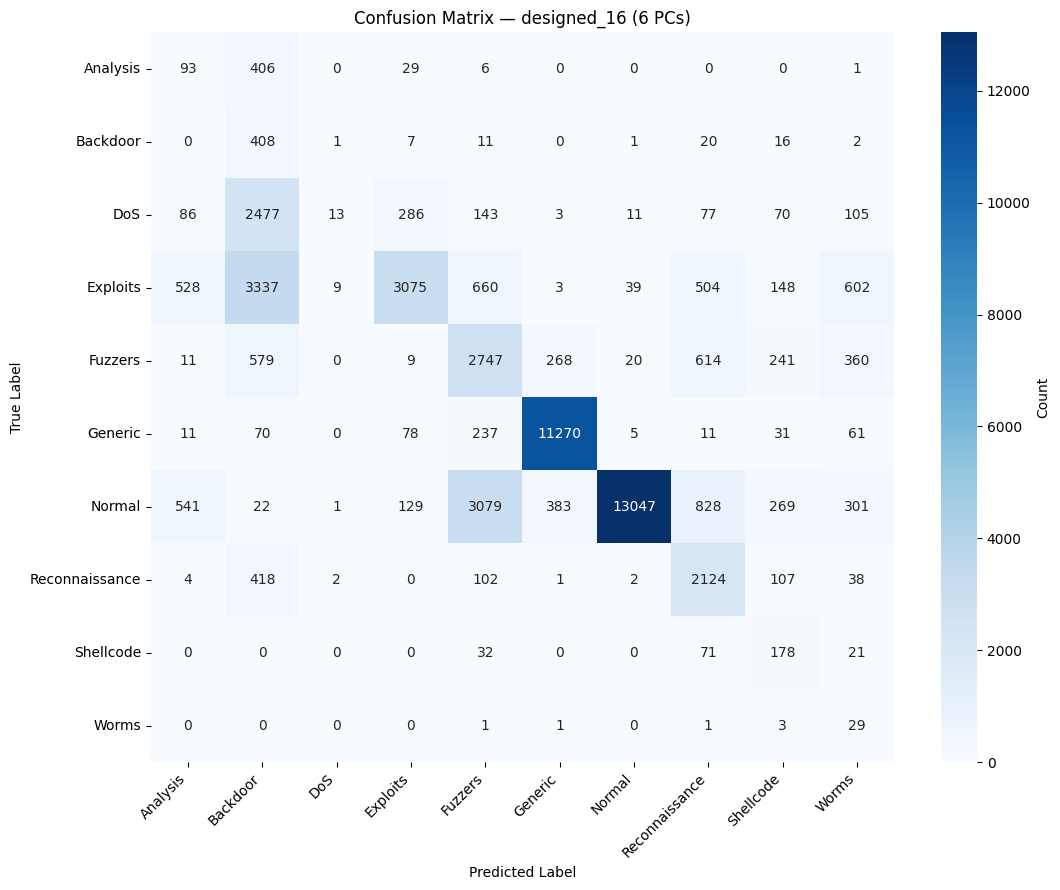

,feature_set,n_features,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,train_time_s,inference_time_s,inference_ms_per_sample,model_params
0,designed_16,6,0.640031,0.819614,0.640031,0.679316,0.383895,567.77454,2.183007,0.04236,59402


In [7]:
# ============================================================================
# DATA LOADING 
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 100)

# Load the optimised features CSV (all 257,673 samples, 6 PCs + target)
dftotal = pd.read_csv('16_optimal_features_ids')

# Drop the unnamed index column if present
if 'Unnamed: 0' in dftotal.columns:
    dftotal = dftotal.drop(columns=['Unnamed: 0'])

DFtotal = dftotal[[
    'Fused_proto_PC3', 'Fused_dur_PC2', 'Fused_proto_PC1',
    'Fused_proto_PC9', 'Fused_proto_PC6', 'Fused_dur_PC1', 
    'attack_cat'
]]

print(DFtotal.shape)
DFtotal.head()

# ============================================================================
# TRAIN/TEST SPLIT 
# ============================================================================
from sklearn.model_selection import train_test_split

y = DFtotal['attack_cat']
x = DFtotal.drop(columns={'attack_cat'})

xtrain_val, xtest, ytrain_val, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print(xtrain_val.shape, xtest.shape)



# ============================================================================
# FEATURE ENGINEERING 
# ============================================================================
FEATURES = [
    'Fused_proto_PC3', 'Fused_dur_PC2', 'Fused_proto_PC1',
    'Fused_proto_PC9', 'Fused_proto_PC6', 'Fused_dur_PC1',
]

x_train = xtrain_val[FEATURES].copy()
x_test  = xtest[FEATURES].copy()

print(x_train.shape, x_test.shape)

# ============================================================================
# CLASS WEIGHTS 
# ============================================================================
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(ytrain_val)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=ytrain_val
)
class_weights = dict(zip(classes, class_weights_array))
print(class_weights)

# ============================================================================
# RESHAPE FOR 1D-CNN 
# ============================================================================
y_train = ytrain_val.values
y_test  = ytest.values
num_classes = len(np.unique(y_train))

n_features = x_train.shape[1]

X_train_cnn = x_train.values.reshape(-1, n_features, 1)
X_test_cnn  = x_test.values.reshape(-1, n_features, 1)

print("X_train_cnn:", X_train_cnn.shape)
print("X_test_cnn: ", X_test_cnn.shape)
print("num_classes:", num_classes)
print("n_features: ", n_features)


import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    Dense, Dropout, Concatenate, BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)

input_layer = Input(shape=(n_features, 1), name="Input")

# -------- Block 1 --------
b1_conv3 = Conv1D(32, 3, padding='same', activation='relu', name="B1_Conv3")(input_layer)
b1_conv5 = Conv1D(32, 5, padding='same', activation='relu', name="B1_Conv5")(input_layer)
b1 = Concatenate(axis=-1, name="B1_Concat")([b1_conv3, b1_conv5])
b1 = BatchNormalization(name="B1_BN")(b1)
b1 = Dropout(0.3, name="B1_Drop")(b1)

# -------- Block 2 --------
b2_conv3 = Conv1D(64, 3, padding='same', activation='relu', name="B2_Conv3")(b1)
b2_conv5 = Conv1D(64, 5, padding='same', activation='relu', name="B2_Conv5")(b1)
b2 = Concatenate(axis=-1, name="B2_Concat")([b2_conv3, b2_conv5])
b2 = BatchNormalization(name="B2_BN")(b2)
b2 = MaxPooling1D(pool_size=2, name="B2_Pool")(b2)
b2 = Dropout(0.3, name="B2_Drop")(b2)

# -------- Aggregation --------
gap = GlobalAveragePooling1D(name="GAP")(b2)

# -------- Classification Head --------
head = Dense(128, activation='relu', name="Dense_128")(gap)
head = Dropout(0.4, name="Head_Drop1")(head)
head = Dense(64, activation='relu', name="Dense_64")(head)
head = Dropout(0.3, name="Head_Drop2")(head)
output = Dense(num_classes, activation='softmax', name="Output")(head)

model = Model(inputs=input_layer, outputs=output, name="CNN_IDS_designed_16f")
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

#............................................................................
# Callbacks
# ============================================================================
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

checkpoint = ModelCheckpoint(
    "cnn_designed_16_best.h5",
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

#............Training..................................................................
import time

start_train = time.time()

history = model.fit(
    X_train_cnn, y_train,
    epochs=100,
    batch_size=256,
    validation_split=0.1,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stop, reduce_lr],
    verbose=1
)

train_time = time.time() - start_train
print(f"\nTraining time: {train_time:.2f} s")


#.......................Evaluatiion...........................................................
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# -------- Inference timing and predictions --------
start_infer = time.time()
y_pred_proba = model.predict(X_test_cnn, verbose=0)
infer_time = time.time() - start_infer
per_sample_ms = (infer_time / len(X_test_cnn)) * 1000

y_pred = np.argmax(y_pred_proba, axis=1)

# -------- Aggregate metrics --------
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1w  = f1_score(y_test, y_pred, average='weighted', zero_division=0)
f1m  = f1_score(y_test, y_pred, average='macro', zero_division=0)

print("\n" + "="*60)
print("TEST SET PERFORMANCE — designed_16 (6 PCs)")
print("="*60)
print(f"Accuracy      : {acc:.4f}")
print(f"Precision (W) : {prec:.4f}")
print(f"Recall (W)    : {rec:.4f}")
print(f"F1 (Weighted) : {f1w:.4f}")
print(f"F1 (Macro)    : {f1m:.4f}")
print(f"Training time : {train_time:.2f} s")
print(f"Inference time: {infer_time:.2f} s ({per_sample_ms:.4f} ms/sample)")
print(f"Model params  : {model.count_params()}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

# -------- Training and validation curves --------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Model Accuracy — designed_34')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], label='Train loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Model Loss — designed_16')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves_designed_16.png', dpi=300)
plt.show()


#....................Confusion Matrix............................................
# -------- Map integer labels back to class names --------
class_names = ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers',
               'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'}
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix — designed_16 (6 PCs)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_designed_16.png', dpi=300)
plt.show()

#...................Save Results...................................................
results = pd.DataFrame([{
    'feature_set': 'designed_16',
    'n_features': n_features,
    'accuracy': acc,
    'precision_weighted': prec,
    'recall_weighted': rec,
    'f1_weighted': f1w,
    'f1_macro': f1m,
    'train_time_s': train_time,
    'inference_time_s': infer_time,
    'inference_ms_per_sample': per_sample_ms,
    'model_params': model.count_params()
}])

results.to_csv('cnn_results_designed_16.csv', index=False)
results


In [8]:
# ============================================================================
# COMPLETE TRAINING HISTORY
# ============================================================================
print("\n" + "=" * 78)
print("COMPLETE TRAINING HISTORY — designed_16")
print("=" * 78)
print(f"{'Epoch':<8}{'Train Acc':<14}{'Val Acc':<14}{'Train Loss':<14}{'Val Loss':<14}")
print("-" * 78)

for epoch in range(len(history.history['accuracy'])):
    print(
        f"{epoch + 1:<8}"
        f"{history.history['accuracy'][epoch]:<14.4f}"
        f"{history.history['val_accuracy'][epoch]:<14.4f}"
        f"{history.history['loss'][epoch]:<14.4f}"
        f"{history.history['val_loss'][epoch]:<14.4f}"
    )

print("=" * 78)
print(f"Total epochs run : {len(history.history['accuracy'])}")

if len(history.history['val_accuracy']) > 0:
    print(f"Best val accuracy: {max(history.history['val_accuracy']):.4f} "
          f"(epoch {np.argmax(history.history['val_accuracy']) + 1})")
    print(f"Best val loss    : {min(history.history['val_loss']):.4f} "
          f"(epoch {np.argmin(history.history['val_loss']) + 1})")
else:
    print("No training history available.")

print("=" * 78)


COMPLETE TRAINING HISTORY — designed_16
Epoch   Train Acc     Val Acc       Train Loss    Val Loss      
------------------------------------------------------------------------------
1       0.4781        0.5985        1.6672        1.1994        
2       0.5366        0.5429        1.4679        1.1132        
3       0.5540        0.5825        1.4059        1.1127        
4       0.5741        0.5644        1.3477        1.0884        
5       0.5767        0.6193        1.3359        1.0163        
6       0.5850        0.5827        1.3310        1.0313        
7       0.5857        0.5740        1.3061        1.0338        
8       0.5809        0.6230        1.3140        0.9804        
9       0.5937        0.6285        1.2811        0.9665        
10      0.5939        0.6285        1.2880        0.9348        
11      0.5962        0.6184        1.2767        0.9931        
12      0.5993        0.6100        1.2621        0.9915        
13      0.5988        0.6168       